In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import pypulseq as pp
import MRzeroCore as mr0
import torchkbnufft as tkbn
from pypulseq import Sequence
import torch.nn.functional as F

/opt/conda/lib/python3.13/site-packages/torch/jit/_script.py:1488: DeprecationWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/opt/conda/lib/python3.13/site-packages/torch/__config__.py:9: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12050). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._show_config()


In [9]:
def main(
    seq: Sequence = pp.Sequence(),
    fov: float = 250e-3,
    Nx: int = 32,
    alpha: float = 5,
    slice_thickness: float = 3e-3,
    TE: float = 3.98e-3,
    TR: float = 3000e-3,
    TI: float = 2200e-3,      
    Nr: int = 500,
    N_dummy: int = 20,
    spokes_per_TR: int = 50,
    rf_spoiling_inc: float = 117,
    write_seq: bool = False,
):
    system = pp.Opts(
        max_grad=28,
        grad_unit="mT/m",
        max_slew=120,
        slew_unit="T/m/s",
        rf_ringdown_time=20e-6,
        rf_dead_time=100e-6,
        adc_dead_time=10e-6,
) 
    deltak = 1 / fov

    rf_inv, gz_inv, _ = pp.make_sinc_pulse(
        flip_angle=np.pi,
        duration=10e-3,
        slice_thickness=slice_thickness,
        apodization=0.5,
        time_bw_product=4,
        system=system,
        return_gz=True,
        use='inversion',
    )

    rf, gz, _ = pp.make_sinc_pulse(
        apodization=0.5,
        duration=2e-3,
        flip_angle=alpha * np.pi / 180,
        slice_thickness=slice_thickness,
        system=system,
        time_bw_product=4,
        return_gz=True,
        use='excitation',
    )

    gx_base = pp.make_trapezoid(
        channel="x", flat_area=Nx * deltak, flat_time=6.4e-3 / 5, system=system
    )
    adc = pp.make_adc(
        num_samples=Nx, duration=gx_base.flat_time, delay=gx_base.rise_time, system=system
    )
    gx_pre_base = pp.make_trapezoid(
        channel="x", area=-gx_base.area / 2, duration=2e-3, system=system
    )
    gz_reph = pp.make_trapezoid(
        channel="z", area=-gz.area / 2, duration=2e-3, system=system
    )
    gx_spoil_base = pp.make_trapezoid(channel="x", area=0.5 * Nx * deltak, system=system)
    gz_spoil = pp.make_trapezoid(channel="z", area=4 / slice_thickness, system=system)

    delay_TE = (
        np.ceil((
            TE
            - pp.calc_duration(gx_pre_base)
            - gz.fall_time
            - gz.flat_time / 2
            - pp.calc_duration(gx_base) / 2
        ) / seq.grad_raster_time)
        * seq.grad_raster_time
    )

    inv_duration = pp.calc_duration(rf_inv, gz_inv)
    delay_TI = (
        np.ceil((
            TI - inv_duration / 2 - pp.calc_duration(gz) / 2
        ) / seq.grad_raster_time)
        * seq.grad_raster_time
    )

    N_segments = int(np.ceil(Nr / spokes_per_TR))

    # TR must fit: inversion + TI delay + spokes_per_TR GRE blocks
    gre_block_duration = (
        pp.calc_duration(gz)
        + pp.calc_duration(gx_pre_base)
        + delay_TE
        + pp.calc_duration(gx_base)
        + pp.calc_duration(gx_spoil_base, gz_spoil)
    )
    min_TR = inv_duration + delay_TI + spokes_per_TR * gre_block_duration
    delay_TR = (
        np.ceil((TR - min_TR) / seq.grad_raster_time) * seq.grad_raster_time
    )
    assert delay_TI > 0, "TI too short for inversion pulse"
    assert delay_TR >= 0, f"TR too short — minimum TR needed: {min_TR*1000:.0f}ms"

    rf_phase = 0
    rf_inc = 0
    spoke_counter = 0

    for seg in range(N_segments):
        # Inversion pulse at start of each segment
        seq.add_block(rf_inv, gz_inv)
        seq.add_block(pp.make_delay(delay_TI))

        for s in range(spokes_per_TR):
            i = seg * spokes_per_TR + s
            if i >= Nr + N_dummy:
                break

            rf.phase_offset = rf_phase / 180 * np.pi
            adc.phase_offset = rf_phase / 180 * np.pi
            rf_inc = (rf_inc + rf_spoiling_inc) % 360
            rf_phase = (rf_phase + rf_inc) % 360

            spoke_idx = i - N_dummy
            if spoke_idx >= 0:
                phi = np.arccos(1 - 2 * (spoke_idx + 0.5) / Nr)
                theta = np.pi * (1 + np.sqrt(5)) * spoke_idx
                kx = np.sin(phi) * np.cos(theta)
                ky = np.sin(phi) * np.sin(theta)
                kz = np.cos(phi)
            else:
                kx, ky, kz = 1, 0, 0

            seq.add_block(rf, gz)
            seq.add_block(
                pp.make_trapezoid(channel="x", area=gx_pre_base.area * kx, duration=2e-3, system=system),
                pp.make_trapezoid(channel="y", area=gx_pre_base.area * ky, duration=2e-3, system=system),
                pp.make_trapezoid(channel="z", area=gx_pre_base.area * kz + gz_reph.area, duration=2e-3, system=system),
            )
            seq.add_block(pp.make_delay(delay_TE))

            gx = pp.make_trapezoid(channel="x", amplitude=gx_base.amplitude * kx, flat_time=gx_base.flat_time, rise_time=gx_base.rise_time, fall_time=gx_base.fall_time, system=system)
            gy = pp.make_trapezoid(channel="y", amplitude=gx_base.amplitude * ky, flat_time=gx_base.flat_time, rise_time=gx_base.rise_time, fall_time=gx_base.fall_time, system=system)
            gz_ro = pp.make_trapezoid(channel="z", amplitude=gx_base.amplitude * kz, flat_time=gx_base.flat_time, rise_time=gx_base.rise_time, fall_time=gx_base.fall_time, system=system)

            if spoke_idx >= 0:
                seq.add_block(gx, gy, gz_ro, adc)
            else:
                seq.add_block(gx, gy, gz_ro)

            seq.add_block(
                pp.make_trapezoid(channel="x", area=gx_spoil_base.area * kx, system=system),
                pp.make_trapezoid(channel="y", area=gx_spoil_base.area * ky, system=system),
                pp.make_trapezoid(channel="z", area=gx_spoil_base.area * kz + gz_spoil.area, system=system),
            )

        seq.add_block(pp.make_delay(delay_TR))
 
    ok, error_report = seq.check_timing()
    print(f"TI={TI*1000:.0f}ms — " + ('Timing check passed' if ok else f'Timing check failed: {error_report}'))
 
    seq.set_definition('FOV', [fov, fov, slice_thickness])
    seq.set_definition('Name', f'ir_kooshball_TI{int(TI*1000)}')
 
    if write_seq:
        seq.write(f"IR_Kooshball_TI{int(TI*1000)}ms.seq")
 
    return seq

TI_GM  =  900e-3
TI_WM  =  600e-3
 
seq_gm  = main(TI=TI_GM,  write_seq=True)
seq_wm  = main(TI=TI_WM,  write_seq=True)

if __name__ == "__main__":
    main(write_seq=True)

/tmp/ipykernel_643/2136472272.py:27: UserWarning: Specified RF delay 0.00 us is less than the dead time 100 us. Delay was increased to the dead time.
  rf_inv, gz_inv, _ = pp.make_sinc_pulse(
/tmp/ipykernel_643/2136472272.py:38: UserWarning: Specified RF delay 0.00 us is less than the dead time 100 us. Delay was increased to the dead time.
  rf, gz, _ = pp.make_sinc_pulse(


TI=2200ms — Timing check passed
TI=900ms — Timing check passed
TI=600ms — Timing check passed
TI=2200ms — Timing check passed


In [4]:
Nx = 32
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
raw_data = np.fromfile("subject04_crisp_v.rawb", dtype=np.uint8).reshape(362, 434, 362)
brain_mask = (raw_data >= 1) & (raw_data <= 3)
cleaned_brain = raw_data * brain_mask

pd_signal = np.zeros_like(raw_data, dtype=np.float32)
pd_signal[raw_data == 1] = 1.0
pd_signal[raw_data == 2] = 0.8
pd_signal[raw_data == 3] = 0.7

phantom_tensor = torch.from_numpy(pd_signal).to(device)

input_5d = phantom_tensor.view(1, 1, 362, 434, 362)

phantom_small = F.interpolate(
    input_5d,
    size=(Nx, Nx, Nx),
    mode='trilinear'
).squeeze()

pd_map = phantom_small
pd_map = pd_map.permute(1,2,0)

t1_map = torch.zeros_like(pd_map)
t1_map = torch.where(pd_map > 0.9, 4.0, t1_map)
t1_map = torch.where((pd_map <= 0.9) & (pd_map > 0.75), 1.3, t1_map)
t1_map = torch.where((pd_map <= 0.75) & (pd_map > 0.1), 0.9, t1_map)
t2_map = torch.zeros_like(pd_map)
t2_map = torch.where(pd_map > 0.9, 0.5, t2_map)
t2_map = torch.where((pd_map <= 0.9) & (pd_map > 0.75), 0.08, t2_map)
t2_map = torch.where((pd_map <= 0.75) & (pd_map > 0.1), 0.07, t2_map)
#t1_map = torch.where(pd_map > 0.5, 0.8, 1.2)
#t2_map = torch.where(pd_map > 0.5, 0.05, 0.09)
t2dash_map = torch.full_like(pd_map, 0.04)
d_map = torch.zeros_like(pd_map)
b0_map = torch.zeros_like(pd_map)
b1_map = torch.ones_like(pd_map).unsqueeze(0)
coil_sens = torch.ones_like(pd_map).unsqueeze(0)
fov_size = torch.tensor([0.256, 0.256, 0.256], device=device)

obj = mr0.VoxelGridPhantom(
    pd_map,
    t1_map,
    t2_map,
    t2dash_map,
    d_map,
    b0_map,
    b1_map,
    coil_sens,
    fov_size
)
 
signal_csf, _ = mr0.util.simulate("IR_Kooshball_TI2200ms.seq", obj)

>>>> Rust - compute_graph(...) >>>
Converting Python -> Rust: 0.0079497 s
Compute Graph
Computing Graph: 12.969437 s
Analyze Graph
Analyzing Graph: 0.7391335 s
Converting Rust -> Python: 12.348285 s
<<<< Rust <<<<


In [14]:
signal_gm, _ = mr0.util.simulate("IR_Kooshball_TI900ms.seq", obj)

>>>> Rust - compute_graph(...) >>>
Converting Python -> Rust: 0.0056708 s
Compute Graph
Computing Graph: 6.6823454 s
Analyze Graph
Analyzing Graph: 0.3470259 s
Converting Rust -> Python: 6.425776 s
<<<< Rust <<<<


In [15]:
signal_wm, _ = mr0.util.simulate("IR_Kooshball_TI600ms.seq", obj)

>>>> Rust - compute_graph(...) >>>
Converting Python -> Rust: 0.0067542 s
Compute Graph
Computing Graph: 9.611764 s
Analyze Graph
Analyzing Graph: 0.5328538 s
Converting Rust -> Python: 9.920117 s
<<<< Rust <<<<


/tmp/ipykernel_643/258863408.py:10: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  ktraj = torch.tensor(mr_seq.get_kspace(), dtype=torch.float32)


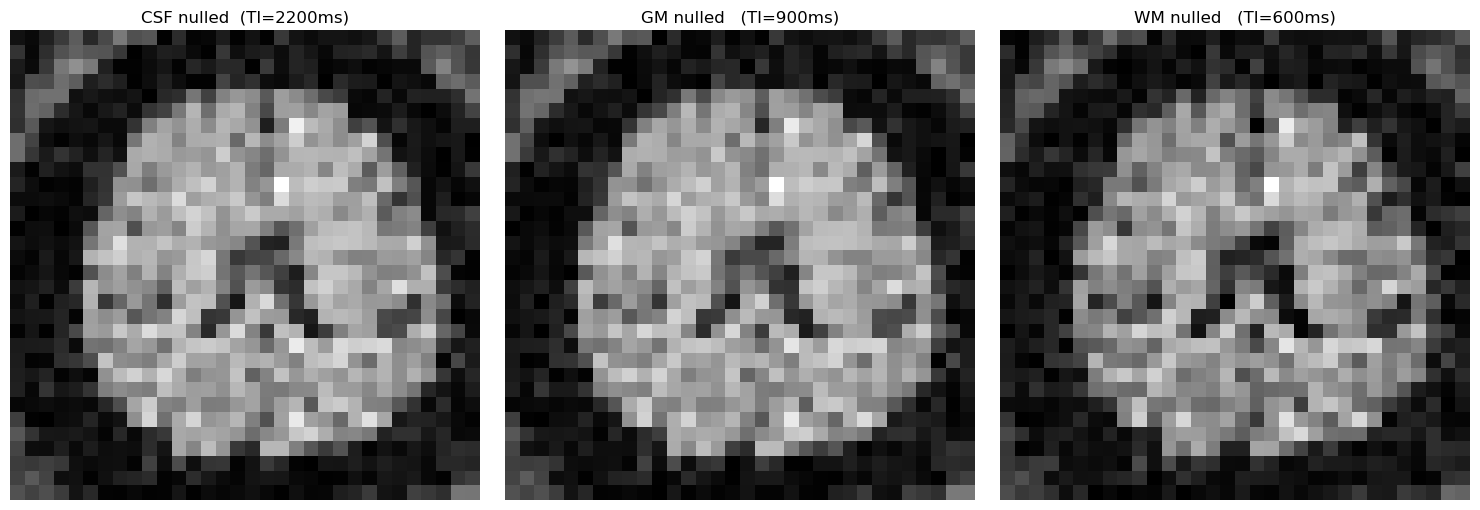

In [16]:
fov = 250e-3
deltak = 1 / fov
Nx = 32
Nx_img, Ny_img, Nz_img = Nx, Nx, Nx
def reconstruct_kooshball(signal, seq_file, Nx_img, Ny_img, Nz_img, device):
    mr_seq = mr0.Sequence.import_file(seq_file)
    
    sig = signal.flatten().to(torch.complex64)

    ktraj = torch.tensor(mr_seq.get_kspace(), dtype=torch.float32)
    ktraj = ktraj.reshape(-1, ktraj.shape[-1])[:, :3].T.contiguous()

    ktraj = ktraj / (deltak * Nx_img / 2) * np.pi
    ktraj = ktraj.clamp(-np.pi, np.pi)
    ktraj = ktraj.unsqueeze(0)

    r = torch.linalg.norm(ktraj[0], dim=0)
    dcomp = (r ** 2).view(1, 1, -1)

    sig = sig.view(1, 1, -1)

    nufft_ob = tkbn.KbNufftAdjoint(
        im_size=(Nx_img, Ny_img, Nz_img),
        grid_size=(2*Nx_img, 2*Ny_img, 2*Nz_img),
    ).to(device)

    image = nufft_ob(sig * dcomp, ktraj)[0, 0]
    return torch.abs(image).cpu().numpy()

img_csf = reconstruct_kooshball(signal_csf, "IR_Kooshball_TI2200ms.seq", Nx_img, Ny_img, Nz_img, device)
img_gm  = reconstruct_kooshball(signal_gm,  "IR_Kooshball_TI900ms.seq",  Nx_img, Ny_img, Nz_img, device)
img_wm  = reconstruct_kooshball(signal_wm,  "IR_Kooshball_TI600ms.seq",  Nx_img, Ny_img, Nz_img, device)
mid = Nz_img // 2

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img_csf[:, :, mid], cmap='gray'); axes[0].set_title('CSF nulled  (TI=2200ms)'); axes[0].axis('off')
axes[1].imshow(img_gm[:, :, mid],  cmap='gray'); axes[1].set_title('GM nulled   (TI=900ms)');  axes[1].axis('off')
axes[2].imshow(img_wm[:, :, mid],  cmap='gray'); axes[2].set_title('WM nulled   (TI=600ms)');  axes[2].axis('off')
plt.tight_layout()
plt.show()